# 03 - Physics-model prediction and residual decay (prototype, 2 rocket bodies)

Goal: for the two sanity-check rocket bodies (SL-3 R/B, NORAD 10114, and H-2A R/B, NORAD 41341),
predict the orbital decay from an atmosphere model and look at what is left over during storms.

For a near-circular orbit, drag shrinks the semi-major axis at
$$\frac{da}{dt} = -B\,\rho\,\sqrt{\mu a}, \qquad B = C_d A / m \ \text{(drag sensitivity, m}^2\text{/kg)}.$$

1. **Orbit samples.** Each decay interval (two consecutive TLEs) is sampled at 24 evenly spaced times.
   SGP4 + skyfield give latitude, longitude, altitude (first half from the start TLE, second half from the end TLE).
2. **Density** $\rho$ at every sample from **NRLMSISE-00** (`pymsis` version 0) and **MSIS 2.1** (version 2.1),
   driven by our own OMNI data: F10.7 of the previous day, 81-day mean F10.7, and the 7-element 3-hour ap history
   (storm-time mode, `geomagnetic_activity=-1`).
3. **Driver** per interval $= -\overline{\rho\sqrt{\mu a}}$ in km/day per unit $B$.
4. **Drag sensitivity** $B$ per object and model = median of observed / driver over **quiet** intervals
   (no storm from 3 days before the storm to 3 days after `recovery_end`). Quiet intervals alternate between
   **fit** (used for $B$) and **holdout** (validation).
5. **Prediction** $= B \times$ driver; **residual** = observed - predicted. Decay is negative, so a negative residual
   means *more* decay than the model predicts. Below, **extra decay** = predicted - observed (positive = model under-predicts).

Storm day 0 is `main_onset` from the storm catalog. Air density is a mediator: it is only used to build this
physics baseline, never as a control.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.spacetrack_io import download_tle_history
from src.orbit import tles_to_frame, drop_duplicate_epochs, decay_rates
from src.storms import load_storms
from src import physics
from src.plots import plot_observed_vs_predicted

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.4g}")

OBJECTS = {10114: "SL-3 R/B (~490 km, 97.5 deg)", 41341: "H-2A R/B (~510 km, 30.6 deg)"}
MODELS = {"nrlmsise00": "NRLMSISE-00", "msis21": "MSIS 2.1"}

## 1. TLEs and decay intervals, Apr 2024 - Apr 2025

In [2]:
records = download_tle_history(list(OBJECTS), "2024-04-01", "2025-04-30",
                               out_name="tle_rocketbodies_2024_2025.json")
tles = drop_duplicate_epochs(tles_to_frame(records))
rates = decay_rates(tles)
print(f"{len(records)} TLEs downloaded, {len(tles)} after removing duplicate epochs, {len(rates)} decay intervals")
rates.groupby("norad_id")[["dt_days", "da_dt_km_per_day"]].describe().T

1884 TLEs downloaded, 1696 after removing duplicate epochs, 1694 decay intervals


norad_id                  10114    41341
dt_days          count      963      731
                 mean    0.4073   0.5359
                 std       0.25   0.3356
                 min    0.06507  0.06511
                 25%     0.2619   0.2623
                 50%     0.3278   0.5243
                 75%     0.5884   0.7853
                 max      4.248    3.281
da_dt_km_per_day count      963      731
                 mean  -0.08656  -0.1302
                 std    0.03587  0.05276
                 min    -0.3954  -0.4884
                 25%    -0.1034  -0.1623
                 50%   -0.08482  -0.1331
                 75%   -0.06516 -0.08898
                 max    0.09594  0.01038

## 2. Space-weather inputs for MSIS

The OMNI table is rebuilt with 3 extra days before 1 Apr 2024, because MSIS needs ap up to 57 h back.
Check: our inputs against the indices that `pymsis` ships with (CelesTrak SW-All). They should agree.

In [3]:
sw = physics.load_msis_weather()
storms = load_storms()

import warnings
from pymsis.utils import get_f107_ap
check_times = pd.date_range("2024-04-05", "2025-04-28", freq="17h")
ours = physics.msis_inputs(sw, check_times)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    theirs = get_f107_ap(check_times.to_numpy())
print(f"F10.7  ours / CelesTrak: median {np.median(ours[0] / theirs[0]):.4f}")
print(f"F10.7a ours / CelesTrak: median {np.median(ours[1] / theirs[1]):.4f}")
print("largest |ap difference| per ap element:", np.abs(ours[2] - theirs[2]).max(axis=0))

F10.7  ours / CelesTrak: median 1.0025
F10.7a ours / CelesTrak: median 1.0025
largest |ap difference| per ap element: [0.5 0.  0.  0.  0.  0.  0. ]


## 3. Density driver, drag sensitivity B, prediction, residual

Results are cached in `data/processed/physics_drivers.parquet` (about 15 s to recompute).

In [4]:
out = physics.run_physics(tles, rates, sw, storms)
out[["role"]].groupby(out["norad_id"]).value_counts().unstack()

role,fit,holdout,storm
norad_id,,,
10114,268,268,427
41341,212,211,308


In [5]:
rows = []
for model, label in MODELS.items():
    B = physics.fit_drag_sensitivity(out, model)
    hold = physics.holdout_residual(out, model).set_index("norad_id")
    for norad_id in OBJECTS:
        q = out[(out["norad_id"] == norad_id) & (out["role"] == "holdout")]
        rows.append({"object": norad_id, "model": label, "B (m^2/kg)": B[norad_id],
                     "holdout mean resid (m/day)": 1000 * hold.loc[norad_id, "mean_resid"],
                     "SE block (m/day)": 1000 * hold.loc[norad_id, "se_block"],
                     "SE naive (m/day)": 1000 * hold.loc[norad_id, "se_naive"],
                     "mean observed (m/day)": 1000 * q["da_dt_km_per_day"].mean(),
                     "sd log ratio": q[f"log_ratio_{model}"].std(),
                     "n holdout": len(q)})
quiet_table = pd.DataFrame(rows)
quiet_table

,object,model,B (m^2/kg),holdout mean resid (m/day),SE block (m/day),SE naive (m/day),mean observed (m/day),sd log ratio,n holdout
0,10114,NRLMSISE-00,0.008778,-0.7283,1.776,0.9909,-80.53,0.3062,268
1,41341,NRLMSISE-00,0.01545,-2.054,2.501,1.513,-120.9,0.1776,211
2,10114,MSIS 2.1,0.009898,-0.9521,1.617,0.9528,-80.53,0.2988,268
3,41341,MSIS 2.1,0.01738,-3.154,1.967,1.405,-120.9,0.1577,211


**Reading the table.** B is the drag sensitivity Cd·A/m. On the held-out quiet intervals the mean residual
should be zero within its standard error. Residuals of neighbouring intervals are correlated (the model's bias
drifts slowly with season and solar activity), so the weekly-block SE is the honest one; the naive SE is shown
for comparison. `sd log ratio` is the typical relative scatter of a single interval.

## 4. Observed vs predicted over the full year (storms shaded, main onset to recovery end)

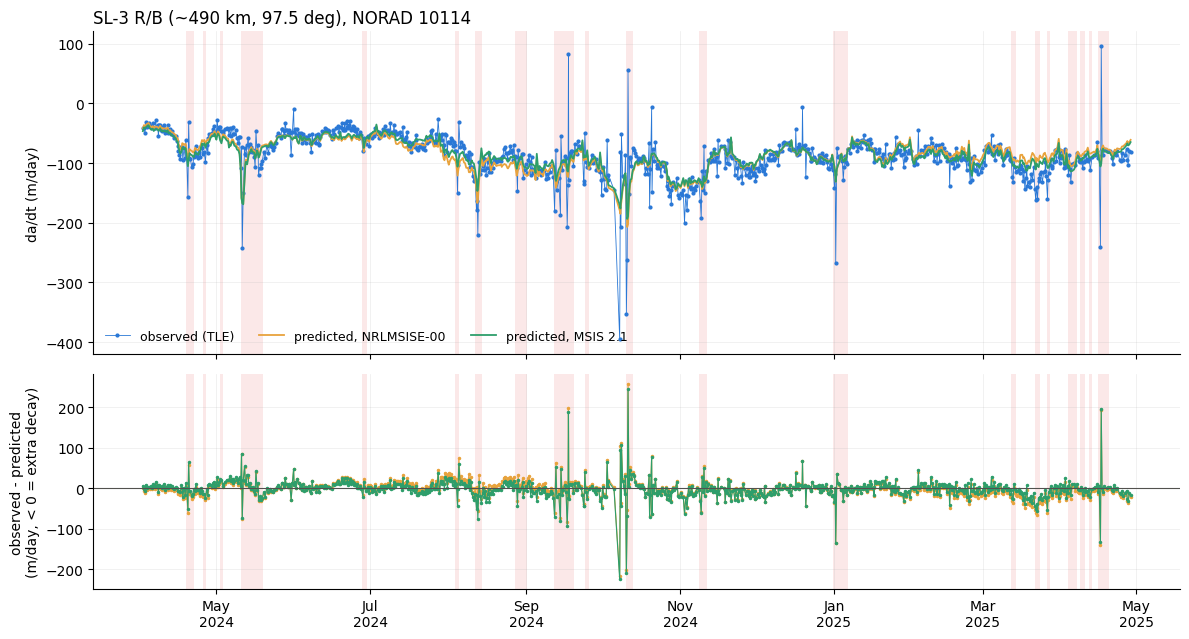

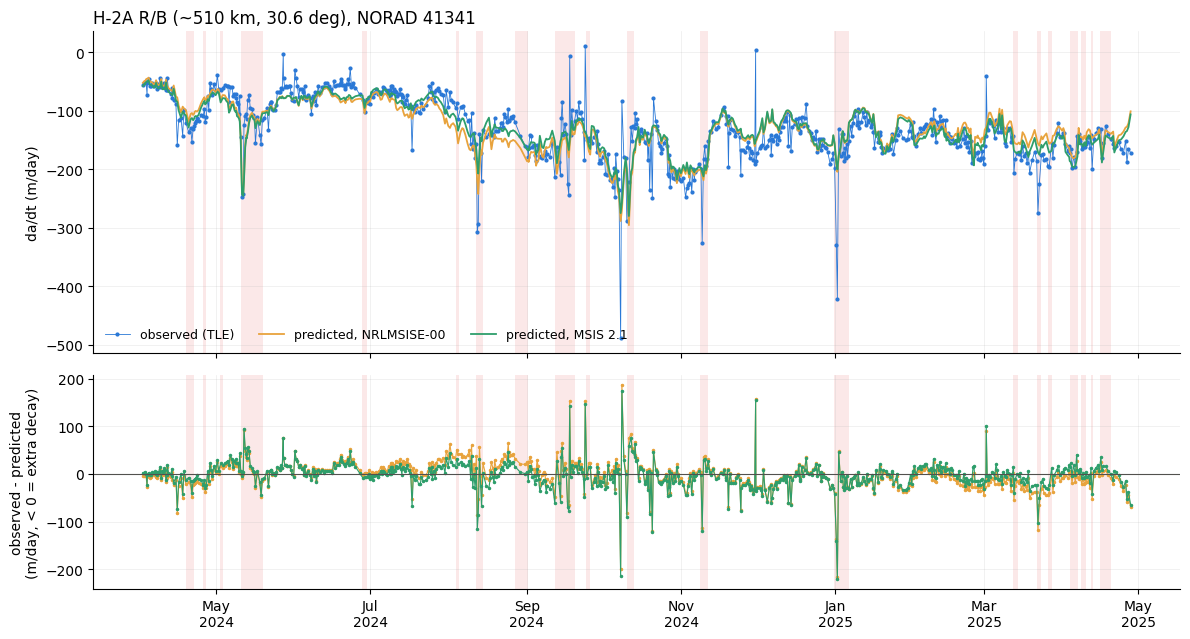

In [6]:
for norad_id, name in OBJECTS.items():
    plot_observed_vs_predicted(out[out["norad_id"] == norad_id], storms, f"{name}, NORAD {norad_id}",
                               out_path=RESULTS / f"physics_year_{norad_id}.png")

## 5. Zoom: May 10 2024 (G5) and Oct 10 2024 (G4)

May 2024: main_onset 2024-05-10 17:00:00, peak 2024-05-11 02:00:00 (-406 nT), recovery_end 2024-05-19 10:00:00
Oct 2024: main_onset 2024-10-10 15:00:00, peak 2024-10-11 01:00:00 (-333 nT), recovery_end 2024-10-13 08:00:00


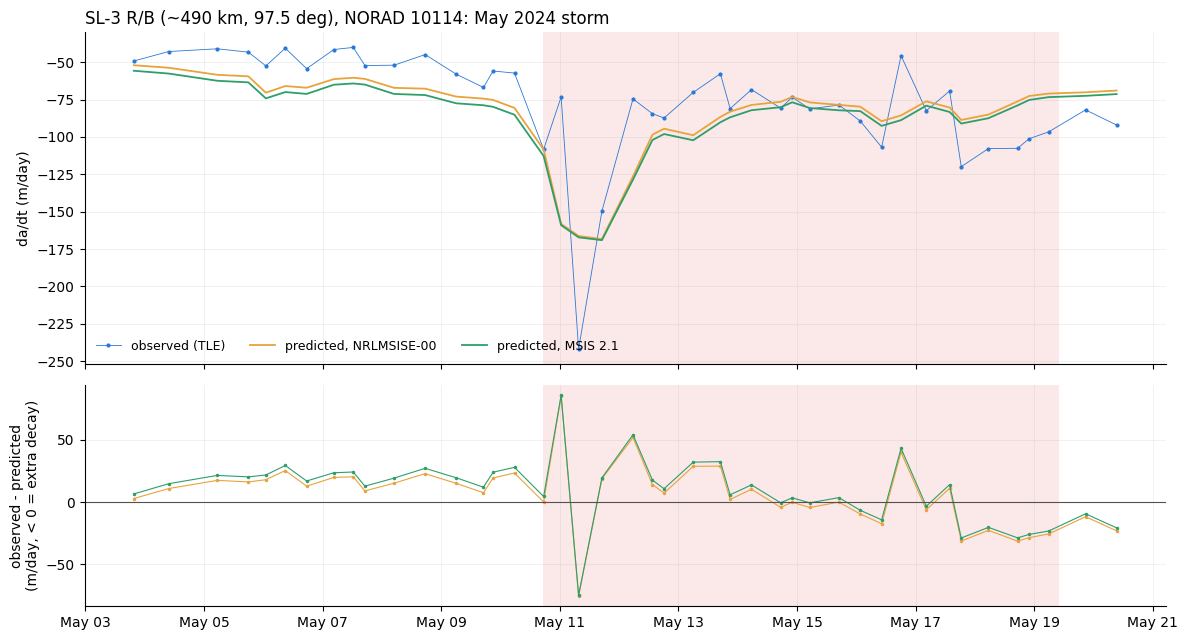

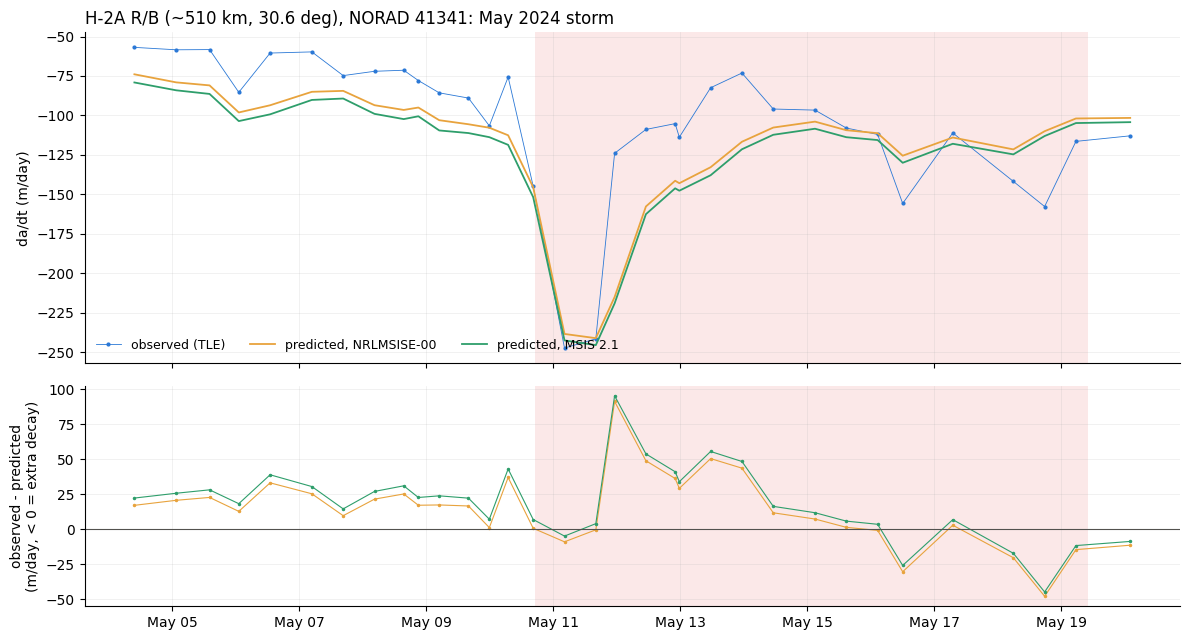

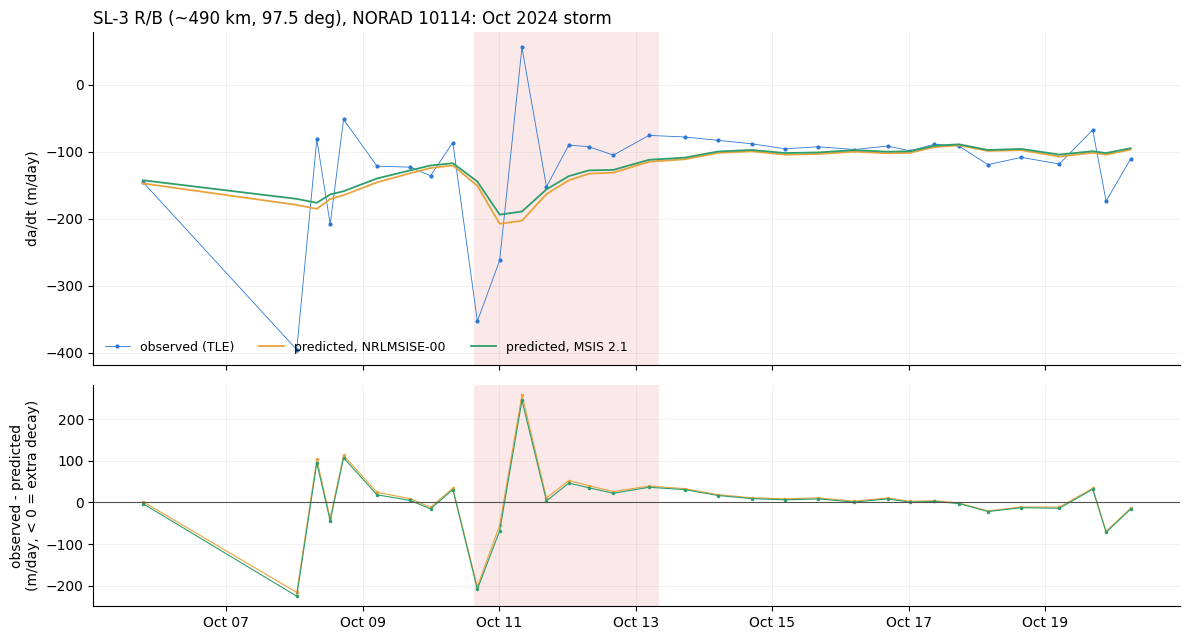

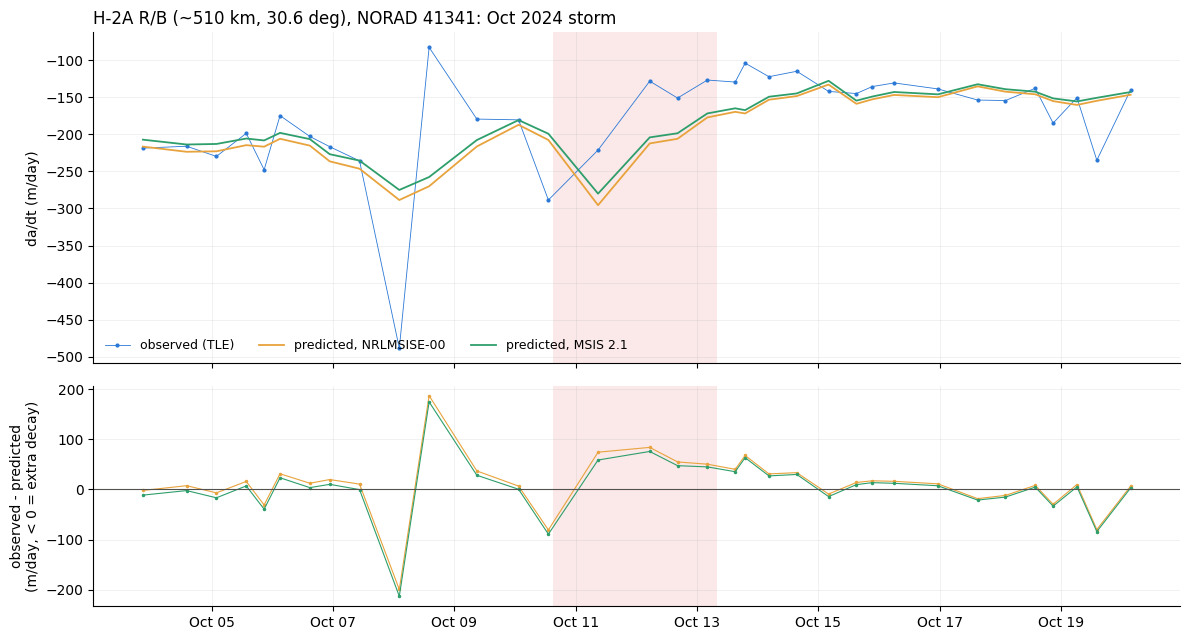

In [7]:
EVENTS = {"May 2024": "2024-05-10", "Oct 2024": "2024-10-10"}
onsets = {}
for event, day in EVENTS.items():
    s = storms[storms["main_onset"].dt.strftime("%Y-%m-%d") == day].iloc[0]
    onsets[event] = s["main_onset"]
    print(f"{event}: main_onset {s['main_onset']}, peak {s['peak_time']} ({s['min_dst']:.0f} nT), recovery_end {s['recovery_end']}")

for event, t0 in onsets.items():
    for norad_id, name in OBJECTS.items():
        plot_observed_vs_predicted(out[out["norad_id"] == norad_id], storms,
                                   f"{name}, NORAD {norad_id}: {event} storm",
                                   start=t0 - pd.Timedelta(days=7), end=t0 + pd.Timedelta(days=10),
                                   out_path=RESULTS / f"physics_zoom_{event.replace(' ', '_')}_{norad_id}.png")

## 6. Residual in the 3 days after main onset

Time-weighted means over intervals whose midpoint is in [main_onset, main_onset + 3 days]; the 3 days *before*
main onset are shown as a reference for the model's pre-storm bias. Units: m/day. `extra` = predicted - observed
(positive = more decay than the model predicts). The SE comes from the scatter of a handful of intervals and is
a lower bound.

In [8]:
rows = []
for event, t0 in onsets.items():
    for window, start in (("3 d before", t0 - pd.Timedelta(days=3)), ("3 d after", t0)):
        for model, label in MODELS.items():
            w = physics.window_residual(out, model, start, days=3)
            for _, r in w.iterrows():
                rows.append({"event": event, "window": window, "object": int(r["norad_id"]), "model": label,
                             "observed": 1000 * r["obs"], "predicted": 1000 * r["pred"],
                             "extra": -1000 * r["resid"], "SE": 1000 * r["se"],
                             "obs/pred": r["obs_over_pred"], "n": int(r["n"])})
storm_table = pd.DataFrame(rows)
storm_table

,event,window,object,model,observed,predicted,extra,SE,obs/pred,n
0,May 2024,3 d before,10114,NRLMSISE-00,-54.93,-71.57,-16.64,2.365,0.7674,7
1,May 2024,3 d before,41341,NRLMSISE-00,-91.29,-108.4,-17.09,4.225,0.8423,8
2,May 2024,3 d before,10114,MSIS 2.1,-54.93,-75.89,-20.96,2.419,0.7238,7
3,May 2024,3 d before,41341,MSIS 2.1,-91.29,-114.3,-23.03,4.201,0.7985,8
4,May 2024,3 d after,10114,NRLMSISE-00,-108.4,-127.9,-19.48,16.33,0.8476,8
5,May 2024,3 d after,41341,NRLMSISE-00,-145.8,-178.7,-32.9,12.72,0.8159,7
6,May 2024,3 d after,10114,MSIS 2.1,-108.4,-130.2,-21.87,16.32,0.8321,8
7,May 2024,3 d after,41341,MSIS 2.1,-145.8,-183.4,-37.6,12.74,0.795,7
8,Oct 2024,3 d before,10114,NRLMSISE-00,-133.5,-149.2,-15.71,36.27,0.8947,8
9,Oct 2024,3 d before,41341,NRLMSISE-00,-223.4,-231.2,-7.822,64.18,0.9662,5


### Storm-time accuracy of the two models

All intervals that overlap a storm window (all 20 storms), per object: mean extra decay and the typical
size of the error (RMS of the log ratio observed / predicted).

In [9]:
rows = []
for model, label in MODELS.items():
    for norad_id in OBJECTS:
        for role in ("holdout", "storm"):
            g = out[(out["norad_id"] == norad_id) & (out["role"] == role)]
            rows.append({"object": norad_id, "model": label, "intervals": role,
                         "mean extra (m/day)": -1000 * g[f"resid_{model}"].mean(),
                         "RMS log ratio": np.sqrt((g[f"log_ratio_{model}"] ** 2).mean()),
                         "n": len(g)})
accuracy = pd.DataFrame(rows).pivot_table(index=["object", "intervals"], columns="model",
                                         values=["mean extra (m/day)", "RMS log ratio"])
accuracy

RMS log ratio             mean extra (m/day)            
model                 MSIS 2.1 NRLMSISE-00           MSIS 2.1 NRLMSISE-00
object intervals                                                         
10114  holdout          0.3002      0.3078             0.9521      0.7283
       storm            0.2352      0.2522               2.23       2.074
41341  holdout          0.1575      0.1772              3.154       2.054
       storm            0.2749      0.2919             0.9695      0.1282

## 7. Summary

**Model inputs.** Our OMNI-based MSIS inputs match the CelesTrak indices that `pymsis` ships with
(3-hour ap identical, F10.7 within 0.3%).

**Quiet-time calibration works.** Drag sensitivity B (m²/kg):

| object | NRLMSISE-00 | MSIS 2.1 |
|---|---|---|
| 10114 SL-3 R/B | 0.0088 | 0.0099 |
| 41341 H-2A R/B | 0.0154 | 0.0174 |

MSIS 2.1 gives ~10% lower densities at ~500 km, so its B is ~10% larger; B absorbs the model's overall
density scale. On the held-out quiet intervals the mean residual is -0.7 to -3.2 m/day (decay of about
-80 and -120 m/day), within 2 weekly-block standard errors (1.6-2.5 m/day) for both objects and both models.
Single intervals still scatter by ~16-30% (sd of log ratio), mostly TLE noise.

**Does the model under-predict storm-time decay? Not in these two storms.** In the 3 days after `main_onset`
the observed decay is 11-29% *smaller* than predicted (obs/pred 0.71-0.89, extra decay -16 to -68 m/day),
so the extra decay is negative, not positive. Two things drive this:
- The model already over-predicts in the 3 days *before* the May storm (obs/pred 0.72-0.84), during the high
  F10.7 of early May 2024. Part of the post-onset gap is this pre-existing bias, not a storm effect.
- The peak (first ~12 h of May 11) is matched well by both models, but the modelled density stays high for
  1-2 days after the peak while the observed decay drops back quickly. This fits the known tendency of MSIS
  to recover too slowly after big storms (fast nitric-oxide cooling is not in the model).
The 3-day windows hold only 4-8 TLE intervals each, with SEs of 7-45 m/day, so none of these single-storm
numbers is precise. Over all intervals inside storm windows (all 20 storms) the mean extra decay is
small: +0.1 to +2.2 m/day.

**MSIS 2.1 vs NRLMSISE-00 during storms: about the same, MSIS 2.1 slightly better.** MSIS 2.1 has a smaller
typical error in storm windows (RMS log ratio 0.235 vs 0.252 for 10114, 0.275 vs 0.292 for 41341) and also in
quiet time. In the 3-day post-onset windows it is slightly closer for Oct 2024 and slightly further off for
May 2024; these differences (2-10 m/day) are well inside the SEs.

**Caveats / next steps.** Two objects only; the TLE series still contains noisy pairs (e.g. 41341 on 8 Oct 2024,
-490 then -80 m/day) because the rolling-median outlier filter is not built yet; TLE-derived decay is smoothed
and delayed relative to the true density, which matters most in the first day of a storm. For the full sample,
use the residual (or log ratio) relative to each object's own pre-storm residual to remove slow model bias
such as the early-May over-prediction.